In [12]:
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import pickle
from hypergraphx import Hypergraph



def hyperedge_homogeneity_list(H):
    edges = [list(e) for e in H.get_edges()]

    # pair_degree[(u, v)] = how many hyperedges contain that pair
    pair_degree = {}
    for edge in edges:
        for u, v in combinations(sorted(edge), 2):
            pair_degree[(u, v)] = pair_degree.get((u, v), 0) + 1

    homogeneity = []
    for edge in edges:
        if len(edge) <= 1:
            homogeneity.append(0.0)
            continue

        pair_values = []
        for u, v in combinations(sorted(edge), 2):
            pair_values.append(pair_degree[(u, v)])

        homogeneity.append(sum(pair_values) / len(pair_values))

    return homogeneity

In [13]:
# All HyperLap datasets: hyperedge homogeneity + basic hypergraph stats
DATASET_DIR = Path("../www21-hyperlap-master/dataset").resolve()

homogeneity_by_dataset: dict = {}

for txt_path in sorted(DATASET_DIR.glob("*_graph.txt")):
    key = txt_path.stem.replace("_graph", "")
    print(key, flush=True)

    edge_list = []
    with open(txt_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens = line.replace(",", " ").split()
            edge_list.append([int(x) for x in tokens])

    H = Hypergraph(edge_list)
    hom_list = hyperedge_homogeneity_list(H)
    edge_sizes = [len(e) for e in H.get_edges()]

    homogeneity_by_dataset[key] = {
        "path": str(txt_path),
        "n_nodes": len(H.get_nodes()),
        "n_edges": len(H.get_edges()),
        "hyperedge_homogeneity": hom_list,
        "mean_homogeneity": np.mean(hom_list),
        "median_homogeneity": np.median(hom_list),
        "std_homogeneity": np.std(hom_list),
        "min_edge_size": min(edge_sizes),
        "max_edge_size": max(edge_sizes),
        "mean_edge_size": np.mean(edge_sizes),
    }


NDC-classes-full
NDC-substances-full
coauth-DBLP-full
coauth-geology-full
coauth-history-full
contact-high
contact-primary
email-Enron-full
email-Eu-full
tags-math
tags-ubuntu
threads-math
threads-ubuntu


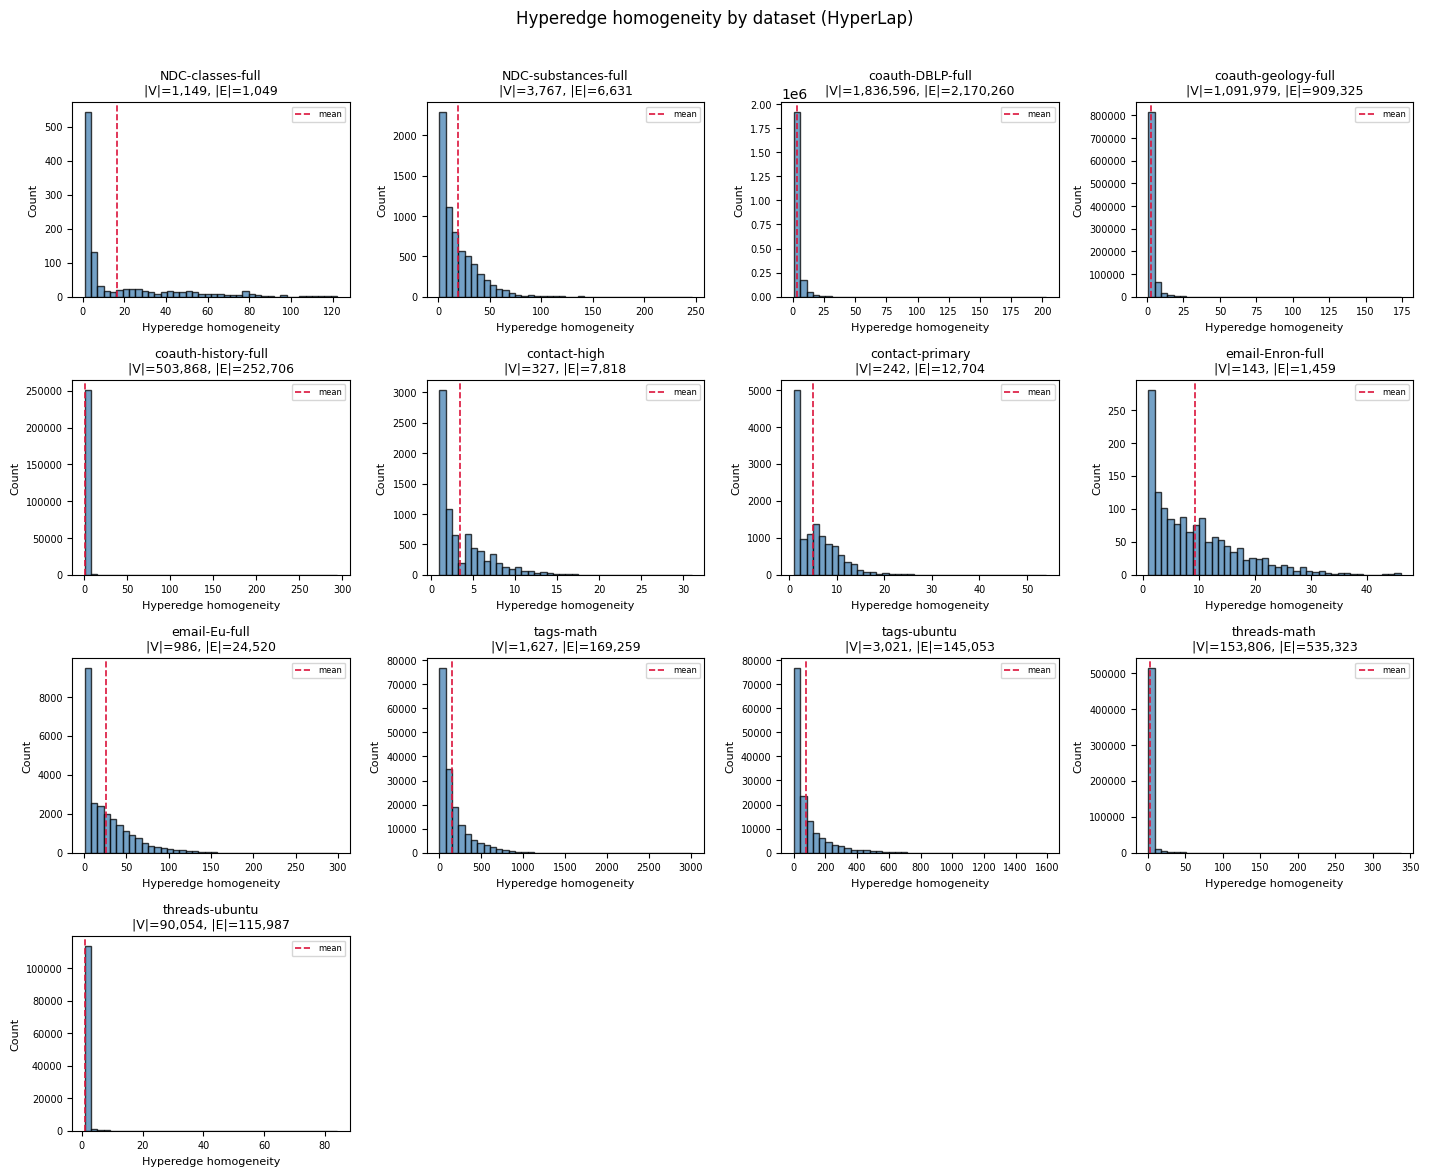

In [14]:
# Facet plot: one histogram per dataset
names = sorted(homogeneity_by_dataset.keys())
n = len(names)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.9 * nrows), squeeze=False)
axes_flat = axes.ravel()

for i, name in enumerate(names):
    ax = axes_flat[i]
    hom = homogeneity_by_dataset[name]["hyperedge_homogeneity"]
    ax.hist(hom, bins=40, edgecolor="black", alpha=0.75, color="steelblue")
    mu = float(homogeneity_by_dataset[name]["mean_homogeneity"])
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, label="mean")
    ax.legend(fontsize=6, loc="best")
    ax.set_title(
        f"{name}\n|V|={homogeneity_by_dataset[name]['n_nodes']:,}, |E|={homogeneity_by_dataset[name]['n_edges']:,}",
        fontsize=9,
    )
    ax.set_xlabel("Hyperedge homogeneity", fontsize=8)
    ax.set_ylabel("Count", fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle("Hyperedge homogeneity by dataset (HyperLap)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


NDC-classes-full: n_edges=1049, n_nodes=1149
contact-high: n_edges=7818, n_nodes=327
contact-primary: n_edges=12704, n_nodes=242
email-Enron-full: n_edges=1459, n_nodes=143
email-Eu-full: n_edges=24520, n_nodes=986
tags-math: n_edges=169259, n_nodes=1627


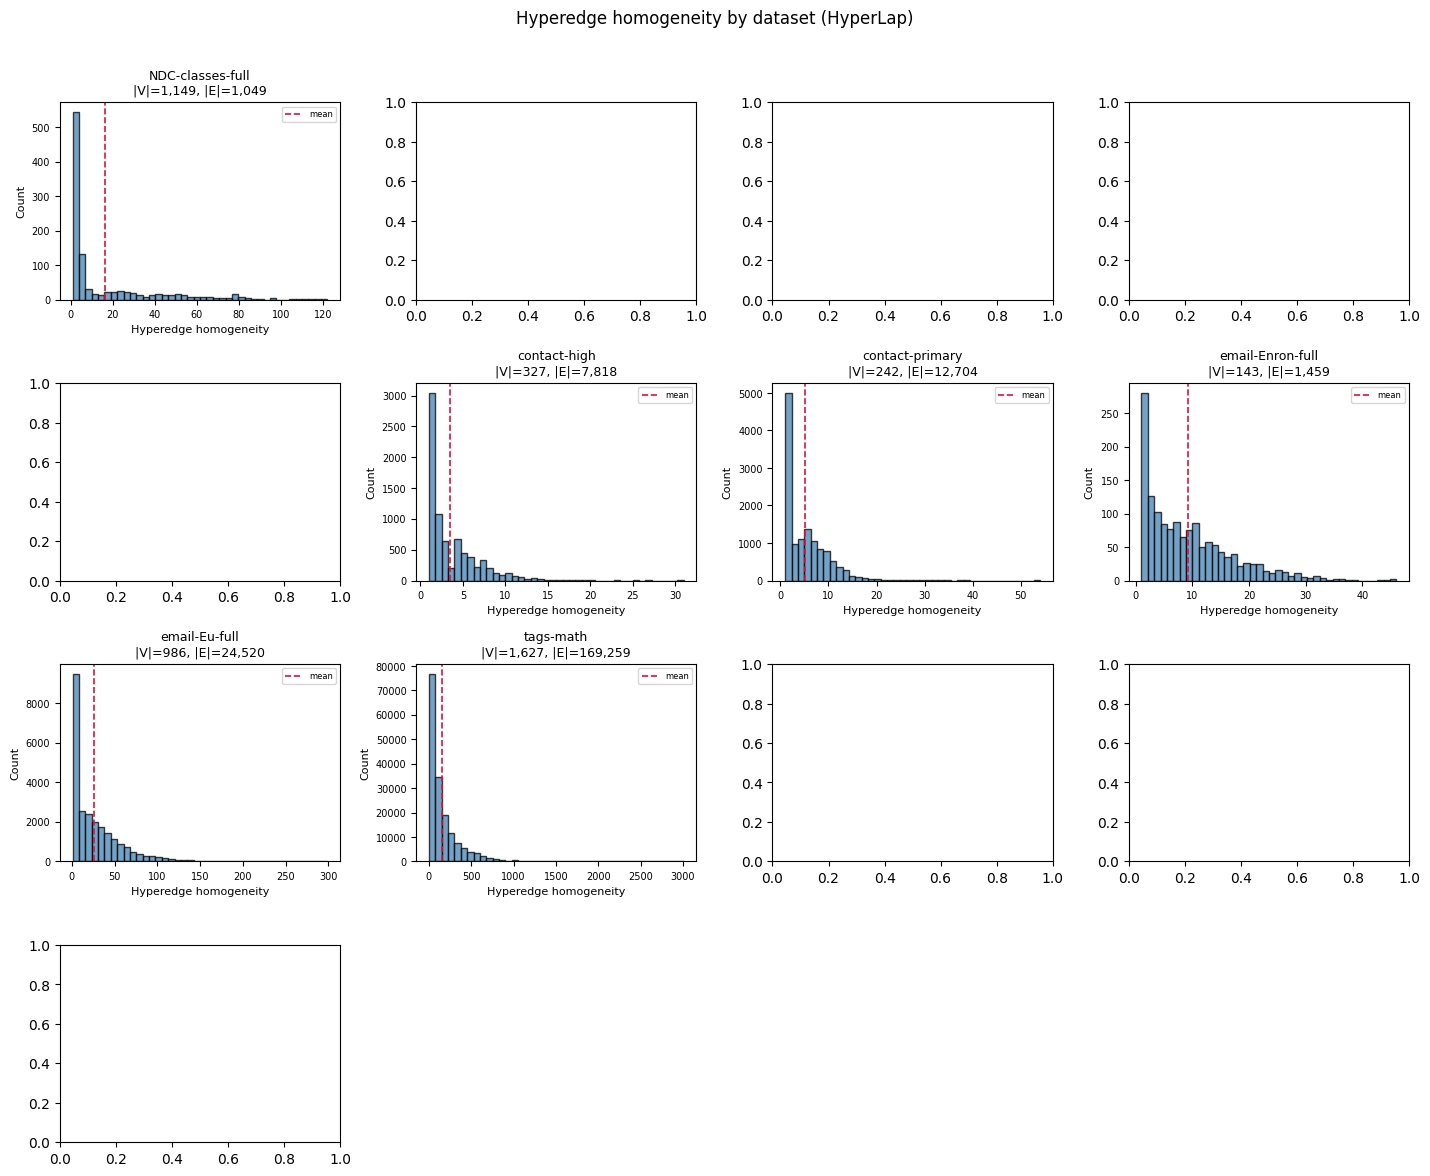

In [48]:
# Facet plot: one histogram per dataset
names = sorted(homogeneity_by_dataset.keys())
n = len(names)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.9 * nrows), squeeze=False)
axes_flat = axes.ravel()

for i, name in enumerate(names):
    # if (homogeneity_by_dataset[name]["n_edges"] > 100000):
    if (homogeneity_by_dataset[name]["n_nodes"] > 2000):
        # print(f"skipping {name}")
        continue 
    ax = axes_flat[i]
    hom = homogeneity_by_dataset[name]["hyperedge_homogeneity"]
    ax.hist(hom, bins=40, edgecolor="black", alpha=0.75, color="steelblue")
    mu = float(homogeneity_by_dataset[name]["mean_homogeneity"])
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, label="mean")
    ax.legend(fontsize=6, loc="best")
    ax.set_title(
        f"{name}\n|V|={homogeneity_by_dataset[name]['n_nodes']:,}, |E|={homogeneity_by_dataset[name]['n_edges']:,}",
        fontsize=9,
    )
    ax.set_xlabel("Hyperedge homogeneity", fontsize=8)
    ax.set_ylabel("Count", fontsize=8)
    ax.tick_params(labelsize=7)
    print(f"{name}: n_edges={homogeneity_by_dataset[name]['n_edges']}, n_nodes={homogeneity_by_dataset[name]['n_nodes']}")

for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle("Hyperedge homogeneity by dataset (HyperLap)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


In [7]:
import pandas as pd
df = pd.read_csv("results/email-Eu-full/hedge_prediction_10perc_20splits_10nw_50wl.csv")
id_cols = ['method', 'config_id', 'p', 'q', 'r', 'gamma', 'delta', 'num_walks', 'walk_length', 'dim']
means = df.groupby(id_cols, dropna=False, as_index=False).agg(auc=('auc', 'mean'), ap=('ap', 'mean'))
wide = df.pivot_table(index=id_cols, columns='fold', values=['auc', 'ap'], aggfunc='first')
wide.columns = [f'{a}_fold{int(b)}' for a, b in wide.columns]
wide = wide.reset_index()
df_wide = means.merge(wide, on=id_cols, how='left')
df_wide[id_cols + ["auc", "ap"]].sort_values("auc", ascending=False)


,method,config_id,p,q,r,gamma,delta,num_walks,walk_length,dim,auc,ap
3,hmrw,hmrw_11,2.0,0.5,1.0,-1.0,0.0,10,50,128,0.919540,0.932050
4,hmrw,hmrw_12,4.0,1.0,1.0,-1.0,0.0,10,50,128,0.919316,0.931933
7,hmrw,hmrw_15,1.0,1.0,2.0,-1.0,0.0,10,50,128,0.918677,0.932148
17,hmrw,hmrw_9,1.0,1.0,1.0,-1.0,0.0,10,50,128,0.918496,0.931716
6,hmrw,hmrw_14,2.0,2.0,1.0,-1.0,0.0,10,50,128,0.917985,0.931712
10,hmrw,hmrw_2,2.0,0.5,1.0,-1.0,-1.0,10,50,128,0.917482,0.930172
11,hmrw,hmrw_3,4.0,1.0,1.0,-1.0,-1.0,10,50,128,0.917229,0.930258
14,hmrw,hmrw_6,1.0,1.0,2.0,-1.0,-1.0,10,50,128,0.917018,0.930828
0,hmrw,hmrw_0,1.0,1.0,1.0,-1.0,-1.0,10,50,128,0.916106,0.929940
13,hmrw,hmrw_5,2.0,2.0,1.0,-1.0,-1.0,10,50,128,0.916033,0.930272


In [10]:
import pandas as pd
df = pd.read_csv("results/email-Enron-full/hedge_prediction_10perc_20splits_10nw_30wl.csv")
id_cols = ['method', 'config_id', 'p', 'q', 'r', 'gamma', 'delta', 'num_walks', 'walk_length', 'dim']
means = df.groupby(id_cols, dropna=False, as_index=False).agg(auc=('auc', 'mean'), ap=('ap', 'mean'))
wide = df.pivot_table(index=id_cols, columns='fold', values=['auc', 'ap'], aggfunc='first')
wide.columns = [f'{a}_fold{int(b)}' for a, b in wide.columns]
wide = wide.reset_index()
df_wide = means.merge(wide, on=id_cols, how='left')
df_wide[id_cols + ["auc", "ap"]].sort_values("auc", ascending=False)


,method,config_id,p,q,r,gamma,delta,num_walks,walk_length,dim,auc,ap
23,hyper2vec,h2v_5,2.0,0.5,0.0,NaN,NaN,10,30,128,0.932732,0.927113
21,hyper2vec,h2v_3,2.0,2.0,0.0,NaN,NaN,10,30,128,0.931403,0.929605
20,hyper2vec,h2v_2,4.0,1.0,0.0,NaN,NaN,10,30,128,0.930963,0.927143
17,hmrw,hmrw_9,1.0,1.0,1.0,-1.0,0.0,10,30,128,0.926580,0.919041
19,hyper2vec,h2v_1,1.0,4.0,0.0,NaN,NaN,10,30,128,0.926295,0.924004
13,hmrw,hmrw_5,2.0,2.0,1.0,-1.0,-1.0,10,30,128,0.925565,0.920681
10,hmrw,hmrw_2,2.0,0.5,1.0,-1.0,-1.0,10,30,128,0.925403,0.917508
14,hmrw,hmrw_6,1.0,1.0,2.0,-1.0,-1.0,10,30,128,0.924849,0.918970
11,hmrw,hmrw_3,4.0,1.0,1.0,-1.0,-1.0,10,30,128,0.924468,0.917609
4,hmrw,hmrw_12,4.0,1.0,1.0,-1.0,0.0,10,30,128,0.924350,0.917289


In [36]:
import pandas as pd
df = pd.read_csv("results/contact-high/hedge_prediction_10perc_20splits_10nw_50wl.csv")
id_cols = ['method', 'config_id', 'p', 'q', 'r', 'gamma', 'delta', 'num_walks', 'walk_length', 'dim']
means = df.groupby(id_cols, dropna=False, as_index=False).agg(auc=('auc', 'mean'), ap=('ap', 'mean'))
wide = df.pivot_table(index=id_cols, columns='fold', values=['auc', 'ap'], aggfunc='first')
wide.columns = [f'{a}_fold{int(b)}' for a, b in wide.columns]
wide = wide.reset_index()
df_wide = means.merge(wide, on=id_cols, how='left')
df_wide[id_cols + ["auc", "ap"]].sort_values("auc", ascending=False)


,method,config_id,p,q,r,gamma,delta,num_walks,walk_length,dim,auc,ap
12,hmrw,hmrw_4,1.0,4.0,1.0,-1.0,-1.0,10,50,128,0.937728,0.949668
9,hmrw,hmrw_17,4.0,1.0,1.0,1.0,0.0,10,50,128,0.934171,0.945659
8,hmrw,hmrw_16,1.0,1.0,1.0,1.0,0.0,10,50,128,0.933670,0.944857
6,hmrw,hmrw_14,2.0,2.0,1.0,-1.0,0.0,10,50,128,0.931534,0.941544
13,hmrw,hmrw_9,1.0,1.0,1.0,-1.0,0.0,10,50,128,0.931203,0.940686
7,hmrw,hmrw_15,1.0,1.0,2.0,-1.0,0.0,10,50,128,0.931075,0.941133
5,hmrw,hmrw_13,1.0,4.0,1.0,-1.0,0.0,10,50,128,0.930929,0.941794
19,hyper2vec,h2v_5,2.0,0.5,0.0,NaN,NaN,10,50,128,0.930837,0.942398
4,hmrw,hmrw_12,4.0,1.0,1.0,-1.0,0.0,10,50,128,0.930835,0.939612
16,hyper2vec,h2v_2,4.0,1.0,0.0,NaN,NaN,10,50,128,0.930612,0.941924


In [ ]:
# Homogeneity-s for datasets in the two HP2PH folders
import pandas as pd
import scipy.io as sio
import scipy.sparse as sp

BASE_DIR = Path("..").resolve()
TARGET_FOLDERS = [
    "github_MingyuanLi88888_HP2PH",
    "github_MingyuanLi88888_HP2PH_1",
]


def _extract_incidence_matrix(mat_dict):
    """Pick the first plausible incidence-like matrix from a .mat payload."""
    preferred_keys = ["S", "H", "A", "incidence", "incidence_matrix"]

    for key in preferred_keys:
        if key in mat_dict:
            value = mat_dict[key]
            if hasattr(value, "shape") and len(value.shape) == 2 and min(value.shape) > 1:
                return key, value

    for key, value in mat_dict.items():
        if key.startswith("__"):
            continue
        if hasattr(value, "shape") and len(value.shape) == 2 and min(value.shape) > 1:
            return key, value

    raise ValueError("No 2D incidence-like matrix found in .mat file")


def _incidence_to_edge_list(incidence):
    if sp.issparse(incidence):
        incidence = incidence.tocsc()
        return [incidence[:, j].indices.tolist() for j in range(incidence.shape[1])]

    arr = np.asarray(incidence)
    return [np.flatnonzero(arr[:, j]).tolist() for j in range(arr.shape[1])]


homogeneity_s_by_file = {}

for folder in TARGET_FOLDERS:
    folder_path = BASE_DIR / folder
    mat_files = sorted(folder_path.glob("*.mat"))

    if not mat_files:
        print(f"No .mat files found in {folder_path}")
        continue

    for mat_file in mat_files:
        print(f"Processing: {folder}/{mat_file.name}")
        mat = sio.loadmat(mat_file)
        matrix_key, incidence = _extract_incidence_matrix(mat)

        edge_list = _incidence_to_edge_list(incidence)
        edge_list = [edge for edge in edge_list if len(edge) >= 2]

        H = Hypergraph(edge_list)
        hom_s = hyperedge_homogeneity_list(H)

        homogeneity_s_by_file[f"{folder}/{mat_file.name}"] = {
            "matrix_key": matrix_key,
            "n_nodes": len(H.get_nodes()),
            "n_edges": len(H.get_edges()),
            "homogeneity_s": hom_s,
            "mean": float(np.mean(hom_s)) if hom_s else float("nan"),
        }


# Plot one histogram per file
names = sorted(homogeneity_s_by_file.keys())
n = len(names)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3 * rows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, name in zip(axes, names):
    vals = homogeneity_s_by_file[name]["homogeneity_s"]
    mu = homogeneity_s_by_file[name]["mean"]

    ax.hist(vals, bins=40, alpha=0.8)
    ax.axvline(mu, linestyle="--", linewidth=1)
    ax.set_title(f"{name}\nmean={mu:.3f}, |E|={len(vals):,}", fontsize=9)
    ax.set_xlabel("homogeneity-s")
    ax.set_ylabel("count")

for ax in axes[n:]:
    ax.axis("off")

plt.show()

pd.DataFrame([
    {
        "dataset": name,
        "matrix_key": d["matrix_key"],
        "n_nodes": d["n_nodes"],
        "n_edges": d["n_edges"],
        "mean_homogeneity_s": d["mean"],
    }
    for name, d in sorted(homogeneity_s_by_file.items())
]).sort_values("dataset")

In [47]:
import pandas as pd
df = pd.read_csv("results/NDC-classes-full/hedge_prediction_10perc_20splits_10nw_100wl.csv")
id_cols = ['method', 'config_id', 'p', 'q', 'r', 'gamma', 'delta', 'num_walks', 'walk_length', 'dim']
means = df.groupby(id_cols, dropna=False, as_index=False).agg(auc=('auc', 'mean'), ap=('ap', 'mean'))
wide = df.pivot_table(index=id_cols, columns='fold', values=['auc', 'ap'], aggfunc='first')
wide.columns = [f'{a}_fold{int(b)}' for a, b in wide.columns]
wide = wide.reset_index()
df_wide = means.merge(wide, on=id_cols, how='left')
df_wide[id_cols + ["auc", "ap"]].sort_values("auc", ascending=False)


,method,config_id,p,q,r,gamma,delta,num_walks,walk_length,dim,auc,ap
13,hyper2vec,h2v_4,0.5,2.0,0.0,NaN,NaN,10,100,128,0.969809,0.959511
10,hyper2vec,h2v_1,1.0,4.0,0.0,NaN,NaN,10,100,128,0.968177,0.958770
12,hyper2vec,h2v_3,2.0,2.0,0.0,NaN,NaN,10,100,128,0.966480,0.954634
9,hyper2vec,h2v_0,1.0,1.0,0.0,NaN,NaN,10,100,128,0.966004,0.952260
11,hyper2vec,h2v_2,4.0,1.0,0.0,NaN,NaN,10,100,128,0.963753,0.949020
14,hyper2vec,h2v_5,2.0,0.5,0.0,NaN,NaN,10,100,128,0.963646,0.946938
7,hmrw,hmrw_17,4.0,1.0,1.0,1.0,0.0,10,100,128,0.952714,0.932173
0,hmrw,hmrw_10,0.5,2.0,1.0,-1.0,0.0,10,100,128,0.952496,0.937282
6,hmrw,hmrw_16,1.0,1.0,1.0,1.0,0.0,10,100,128,0.951720,0.930723
4,hmrw,hmrw_14,2.0,2.0,1.0,-1.0,0.0,10,100,128,0.951022,0.934954


In [41]:
import pickle
import sys
from datetime import datetime
from pathlib import Path

import pandas as pd
from hypergraphx import Hypergraph

from src.hypergraph_train_test_split import (
    evaluate,
    generate_negative_hyperedges,
    split_hypergraph_train_test,
)
from src.utils import hmrw_embeddings, hyper2vec_embeddings


def load_txt(path: Path) -> Hypergraph:
    edges = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            edges.append([int(x) for x in line.replace(",", " ").split()])
    return Hypergraph(edges)


graph_path = "../www21-hyperlap-master/dataset/NDC-substances-full_graph.txt"
graph = Path(graph_path)
H = load_txt(graph)

In [45]:
graph_path = "../www21-hyperlap-master/dataset/NDC-classes-full_graph.txt"
graph = Path(graph_path)
Hc = load_txt(graph)

In [44]:
len(H.connected_components())

99

In [ ]:
len(Hc.connected_components())

171

Load datasets

Processing: github_MingyuanLi88888_HP2PH/aminer_cocitation.mat
Processing: github_MingyuanLi88888_HP2PH/aminer_coreference.mat
Processing: github_MingyuanLi88888_HP2PH/citeseer_cocitation.mat
Processing: github_MingyuanLi88888_HP2PH/citeseer_coreference.mat
Processing: github_MingyuanLi88888_HP2PH/cora_cocitation.mat
Processing: github_MingyuanLi88888_HP2PH/cora_coreference.mat
Processing: github_MingyuanLi88888_HP2PH/dblp_coauthorship.mat
Processing: github_MingyuanLi88888_HP2PH_1/contact_highschool.mat
Processing: github_MingyuanLi88888_HP2PH_1/uchoice_Walmart_Depts.mat
Processing: github_MingyuanLi88888_HP2PH_1/uchoice_bakery.mat


KeyboardInterrupt: 

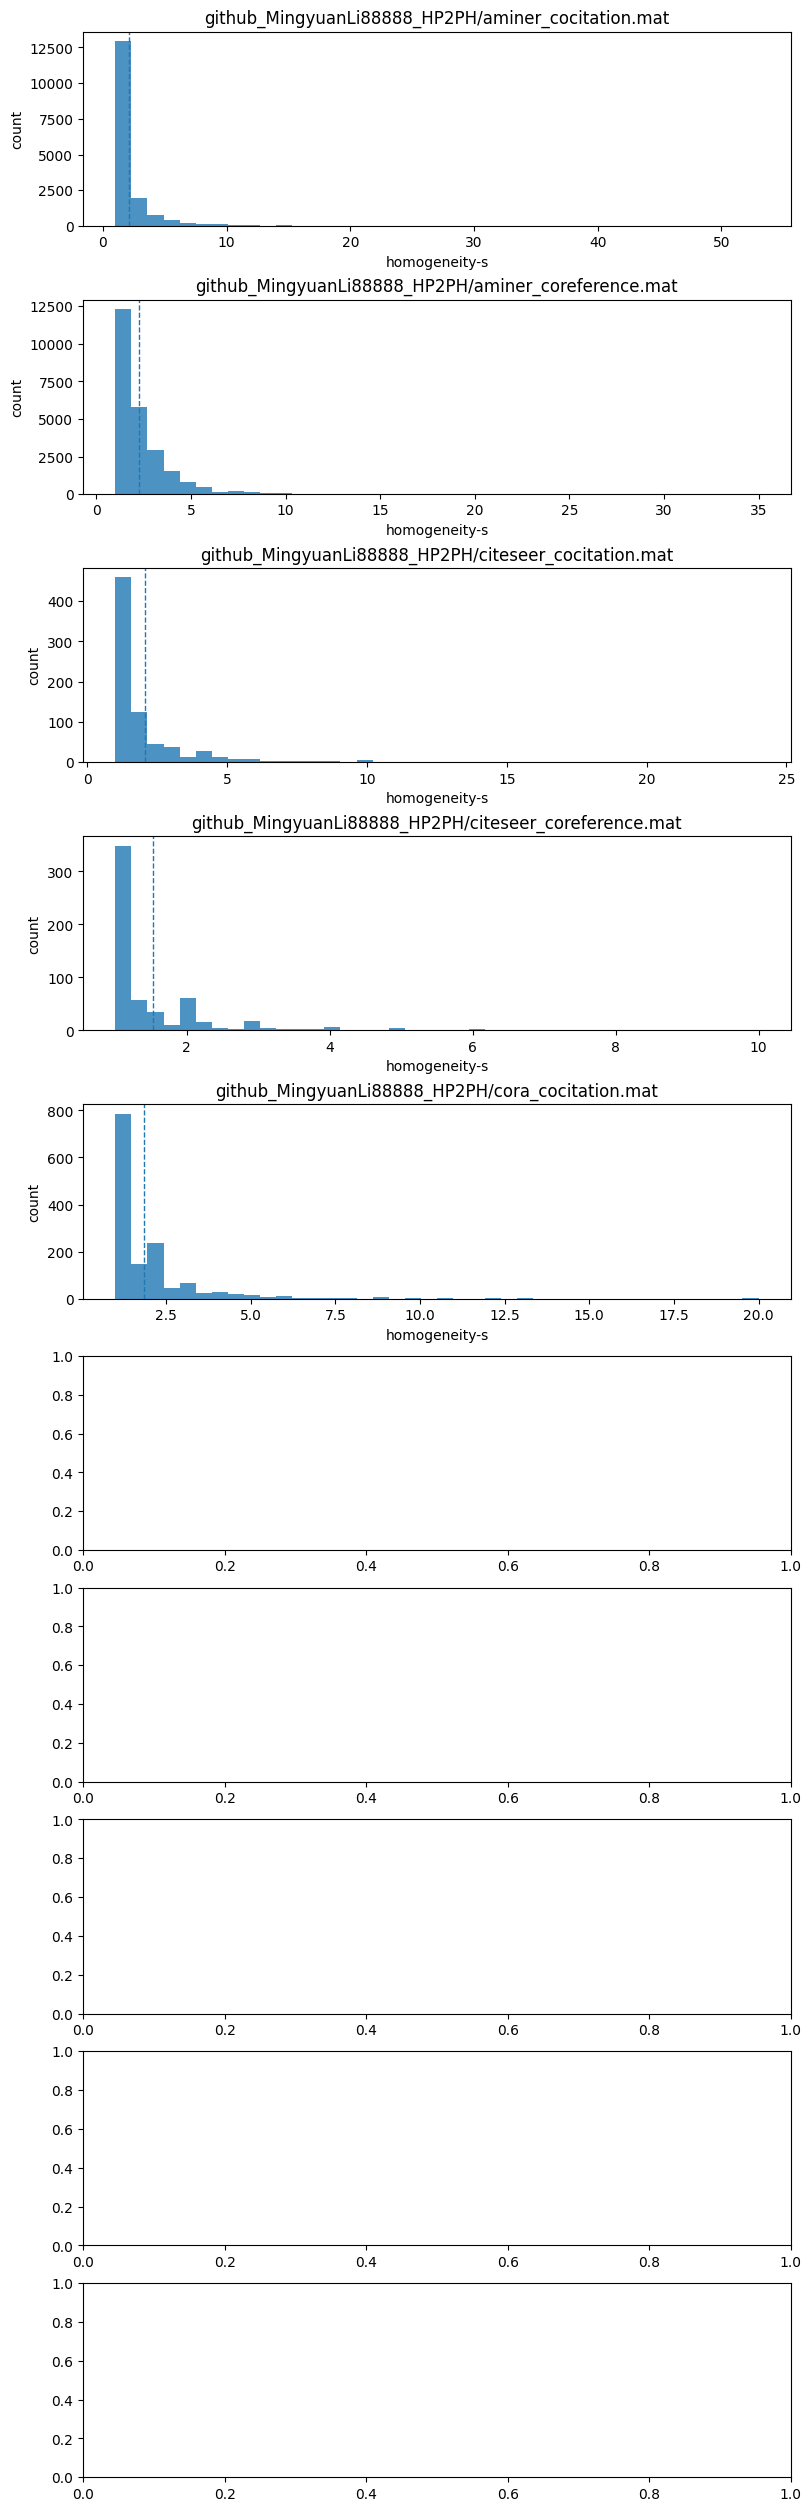

In [51]:
# Simple homogeneity-s plot for the two HP2PH folders
import scipy.io as sio

folders = [
    Path("../github_MingyuanLi88888_HP2PH"),
    Path("../github_MingyuanLi88888_HP2PH_1"),
]

results = {}

for folder in folders:
    for mat_file in sorted(folder.glob("*.mat")):
        name = f"{folder.name}/{mat_file.name}"
        print(f"Processing: {name}")

        mat = sio.loadmat(mat_file)
        S = mat.get("S")
        if S is None:
            print(f"  skipped ({name} has no 'S' matrix)")
            continue

        # columns of S are hyperedges
        if hasattr(S, "tocsc"):
            S = S.tocsc()  # sparse-safe column slicing
            edges = [S[:, j].indices.tolist() for j in range(S.shape[1])]
        else:
            edges = [np.flatnonzero(S[:, j]).tolist() for j in range(S.shape[1])]

        edges = [e for e in edges if len(e) >= 2]

        H = Hypergraph(edges)
        hs = hyperedge_homogeneity_list(H)
        results[name] = {
            "hs": hs,
            "n_nodes": len(H.get_nodes()),
            "n_edges": len(H.get_edges()),
            "mean": float(np.mean(hs)) if hs else float("nan"),
        }

names = sorted(results)
fig, axes = plt.subplots(len(names), 1, figsize=(8, 2.8 * len(names)), constrained_layout=True)
axes = np.atleast_1d(axes)

for ax, name in zip(axes, names):
    hs = results[name]["hs"]
    mu = results[name]["mean"]
    n_nodes = results[name]["n_nodes"]
    n_edges = results[name]["n_edges"]

    ax.hist(hs, bins=40, alpha=0.8)
    ax.axvline(mu, linestyle="--", linewidth=1)
    ax.set_title(f"{name}\\n|V|={n_nodes:,}, |E|={n_edges:,}, mean={mu:.3f}")
    ax.set_xlabel("homogeneity-s")
    ax.set_ylabel("count")

plt.show()